# Linear Models: Regression and Exceedance Probability

**Objective:** Fit linear models (OLS, Ridge, Lasso) to predict log nitrate, and logistic regression (no penalty, L2, L1) to predict the probability of exceeding 10 mg/L. All models use the 50 selected features (`load_model_data()`) and the shared 10 km spatial folds (folds 0–3; fold 4 is the untouched holdout).

In [1]:
import sys
from pathlib import Path

# Set root
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from src.features.preprocessing import load_model_data
from src.evaluation import splits
from src.evaluation.make_splits import load_split

In [2]:
# Load the cleaned/merged dataset

X, y, meta = load_model_data()
FEATURES = list(X.columns)

data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y))
print(data["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(data["holdout"].sum()))

# df = pd.read_csv(DATA_PATH, dtype={"gm_well_id": "string"}, parse_dates=["gm_samp_collection_date"])
# df = load_split(df)

# print(df["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(df["holdout"].sum()))

{0: 1035, 1: 972, 2: 1143, 3: 1041, 4: 1089} | holdout rows: 1089


In [3]:
# Set the training folds and the holdout

train_val = data[~data["holdout"]].reset_index(drop=True)       # Training set with 4 folds


X_tv = train_val[FEATURES]
y_tv = train_val["log_nitrate"]

# Print the sizes of the training folds
print(train_val["fold"].value_counts().sort_index().to_dict())

{0: 1035, 1: 972, 2: 1143, 3: 1041}


## 0. Baseline (Dummy)

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error

In [5]:
def make_model():
    """Replace with your model. A new, untrained model is created for every fold."""
    return DummyRegressor(strategy="mean")        # baseline: always predicts the training mean

oof_pred = np.full(len(train_val), np.nan)        # out-of-fold prediction for every row
fold_scores = []

for train, test in splits.iter_folds(train_val["fold"]):
    model = make_model()
    model.fit(X_tv[train], y_tv[train])
    oof_pred[test] = model.predict(X_tv[test])

    fold = int(train_val.loc[test, "fold"].iloc[0])
    fold_scores.append({"fold": fold,
                        "rmse_log": root_mean_squared_error(y_tv[test], oof_pred[test])})

fold_scores = pd.DataFrame(fold_scores)
exceeds = np.expm1(y_tv) > 10
print(fold_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, oof_pred):.3f}")
print(f"Accuracy of the >10 mg/L call: {np.mean((np.expm1(oof_pred) > 10) == exceeds):.3f}")


 fold  rmse_log
    0     1.227
    1     1.183
    2     1.222
    3     1.314
Overall RMSE (log): 1.238
Accuracy of the >10 mg/L call: 0.662


Save this last file for the final evaluation (when we have compared all of our models and have chosen a final one).

## 1. Linear Regression (OLS)

**Objective:** Fit an ordinary least squares model on log nitrate as the simplest linear reference. Features are median-imputed and standardized inside a pipeline fitted on each training fold. Because drainage groups and hydrologic groups each sum to 100%, one class from each set (moderate drainage, hydrologic group B) is dropped as the reference category to avoid perfect collinearity.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.metrics import r2_score

REFERENCE_COLS = ["soil_drainage_moderate_pct", "soil_hydgrpdcd_pct_b"]
LINEAR_FEATURES = [f for f in FEATURES if f not in REFERENCE_COLS]


def evaluate_regression(make_model, features):
    """Fit a new model on each training fold and score it on the held-out fold.
    If the model is a GridSearchCV, alpha is tuned only on that fold's training folds."""
    oof = np.full(len(train_val), np.nan)
    scores = []
    for train, test in splits.iter_folds(train_val["fold"]):
        model = make_model()
        fit_kwargs = {"groups": train_val.loc[train, "fold"]} if isinstance(model, GridSearchCV) else {}
        model.fit(X_tv.loc[train, features], y_tv[train], **fit_kwargs)
        oof[test] = model.predict(X_tv.loc[test, features])
        row = {"fold": int(train_val.loc[test, "fold"].iloc[0]),
               "rmse_log": root_mean_squared_error(y_tv[test], oof[test]),
               "r2": r2_score(y_tv[test], oof[test])}
        if isinstance(model, GridSearchCV):
            row.update(model.best_params_)
        scores.append(row)
    return pd.DataFrame(scores), oof


def make_linear():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression())


ols_scores, ols_oof = evaluate_regression(make_linear, LINEAR_FEATURES)
print(ols_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, ols_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, ols_oof):.3f}")

 fold  rmse_log     r2
    0     1.097  0.195
    1     1.343 -0.289
    2     1.154  0.102
    3     1.121  0.252
Overall RMSE (log): 1.179 | Overall R²: 0.088


 ## 2. Ridge and Lasso

**Objective:** Penalize large coefficients to make the linear model more stable in areas it has not seen. The penalty `alpha` is chosen by nested cross-validation: within each outer training set, each of the three remaining spatial folds is held out in turn (leave-one-fold-out) to select `alpha`, so the outer test fold is never used for tuning.

In [7]:
RIDGE_ALPHAS = np.logspace(0, 6, 13)   # 1 to 1,000,000


def make_ridge():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())
    return GridSearchCV(pipe, {"ridge__alpha": RIDGE_ALPHAS}, cv=LeaveOneGroupOut(),
                        scoring="neg_root_mean_squared_error")


ridge_scores, ridge_oof = evaluate_regression(make_ridge, LINEAR_FEATURES)
print(ridge_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, ridge_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, ridge_oof):.3f}")

 fold  rmse_log     r2  ridge__alpha
    0     1.080  0.220      3162.278
    1     1.237 -0.094      3162.278
    2     1.135  0.132      3162.278
    3     1.115  0.260     10000.000
Overall RMSE (log): 1.141 | Overall R²: 0.145


In [8]:
LASSO_ALPHAS = [0.001, 0.003, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5]


def make_lasso():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Lasso(max_iter=20_000))
    return GridSearchCV(pipe, {"lasso__alpha": LASSO_ALPHAS}, cv=LeaveOneGroupOut(),
                        scoring="neg_root_mean_squared_error")


lasso_scores, lasso_oof = evaluate_regression(make_lasso, LINEAR_FEATURES)
print(lasso_scores.round(3).to_string(index=False))
print(f"Overall RMSE (log): {root_mean_squared_error(y_tv, lasso_oof):.3f} | "
      f"Overall R²: {r2_score(y_tv, lasso_oof):.3f}")

 fold  rmse_log     r2  lasso__alpha
    0     1.094  0.199          0.10
    1     1.256 -0.127          0.03
    2     1.137  0.129          0.10
    3     1.095  0.286          0.10
Overall RMSE (log): 1.145 | Overall R²: 0.140


## 3. Probability of Exceeding 10 mg/L (Logistic Regression)

**Objective:** Predict the probability that a sample exceeds the 10 mg/L drinking-water limit. Logistic regression is the classification counterpart of the linear models above: no penalty (counterpart of OLS), L2 (Ridge) and L1 (Lasso). The regularization strength `C` (the inverse of `alpha`; smaller `C` means a stronger penalty) is chosen by nested cross-validation, minimizing the Brier score. Models are evaluated with AUC (how well they rank exceeding vs. non-exceeding samples) and Brier skill score (improvement in probability error over always predicting the training exceedance rate).

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

exceeds_tv = (np.expm1(y_tv) > 10).to_numpy()


def evaluate_classification(make_model, features):
    """Fit a new classifier on each training fold and score its probabilities on the held-out fold."""
    oof = np.full(len(train_val), np.nan)
    scores = []
    for train, test in splits.iter_folds(train_val["fold"]):
        model = make_model()
        fit_kwargs = {"groups": train_val.loc[train, "fold"]} if isinstance(model, GridSearchCV) else {}
        model.fit(X_tv.loc[train, features], exceeds_tv[train], **fit_kwargs)
        oof[test] = model.predict_proba(X_tv.loc[test, features])[:, 1]
        baseline = brier_score_loss(exceeds_tv[test], np.full(test.sum(), exceeds_tv[train].mean()))
        row = {"fold": int(train_val.loc[test, "fold"].iloc[0]),
               "auc": roc_auc_score(exceeds_tv[test], oof[test]),
               "brier_skill": 1 - brier_score_loss(exceeds_tv[test], oof[test]) / baseline}
        if isinstance(model, GridSearchCV):
            row.update(model.best_params_)
        scores.append(row)
    return pd.DataFrame(scores), oof


def summarize_classification(scores, oof):
    print(scores.round(3).to_string(index=False))
    print(f"Mean AUC: {scores['auc'].mean():.3f} | Mean Brier skill: {scores['brier_skill'].mean():.3f}")


dummy_clf_scores, dummy_clf_oof = evaluate_classification(
    lambda: DummyClassifier(strategy="prior"), LINEAR_FEATURES)
summarize_classification(dummy_clf_scores, dummy_clf_oof)

 fold  auc  brier_skill
    0  0.5          0.0
    1  0.5          0.0
    2  0.5          0.0
    3  0.5          0.0
Mean AUC: 0.500 | Mean Brier skill: 0.000


In [10]:
C_VALUES = np.logspace(-4, 2, 13)   # 0.0001 to 100


def make_logistic_plain():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=np.inf, max_iter=5000))


def make_logistic(l1_ratio):
    """l1_ratio=0 -> L2 (Ridge-like), l1_ratio=1 -> L1 (Lasso-like)."""
    solver = "saga" if l1_ratio == 1 else "lbfgs"
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(l1_ratio=l1_ratio, solver=solver, max_iter=5000))
    return GridSearchCV(pipe, {"logisticregression__C": C_VALUES}, cv=LeaveOneGroupOut(),
                        scoring="neg_brier_score")


print("No penalty")
logit_scores, logit_oof = evaluate_classification(make_logistic_plain, LINEAR_FEATURES)
summarize_classification(logit_scores, logit_oof)

print("\nL2 (Ridge)")
logit_l2_scores, logit_l2_oof = evaluate_classification(lambda: make_logistic(0), LINEAR_FEATURES)
summarize_classification(logit_l2_scores, logit_l2_oof)

print("\nL1 (Lasso)")
logit_l1_scores, logit_l1_oof = evaluate_classification(lambda: make_logistic(1), LINEAR_FEATURES)
summarize_classification(logit_l1_scores, logit_l1_oof)

No penalty
 fold   auc  brier_skill
    0 0.755        0.155
    1 0.651       -0.140
    2 0.756        0.186
    3 0.776        0.165
Mean AUC: 0.735 | Mean Brier skill: 0.091

L2 (Ridge)
 fold   auc  brier_skill  logisticregression__C
    0 0.781        0.194                  0.003
    1 0.624       -0.069                  0.003
    2 0.747        0.178                  0.001
    3 0.799        0.235                  0.001
Mean AUC: 0.738 | Mean Brier skill: 0.135

L1 (Lasso)
 fold   auc  brier_skill  logisticregression__C
    0 0.775        0.174                  0.010
    1 0.629       -0.085                  0.032
    2 0.748        0.176                  0.010
    3 0.793        0.230                  0.010
Mean AUC: 0.736 | Mean Brier skill: 0.124


In [11]:
risk_level = pd.cut(logit_l2_oof, [0, 0.25, 0.5, 1.0001], right=False,
                    labels=["Low (<25%)", "Moderate (25-50%)", "High (>50%)"])

risk_summary = (pd.DataFrame({"risk_level": risk_level, "exceeds": exceeds_tv})
                .groupby("risk_level", observed=False)["exceeds"]
                .agg(samples="size", observed_exceedance_rate="mean"))
risk_summary.round(3)

,samples,observed_exceedance_rate
risk_level,,
Low (<25%),1350,0.053
Moderate (25-50%),1933,0.445
High (>50%),908,0.534


## 4. Results Summary

In [12]:
reg_preds = {"Dummy (mean)": oof_pred, "Linear regression": ols_oof, "Ridge": ridge_oof, "Lasso": lasso_oof}
reg_folds = {"Dummy (mean)": None, "Linear regression": ols_scores, "Ridge": ridge_scores, "Lasso": lasso_scores}

regression_results = pd.DataFrame({
    "model": list(reg_preds),
    "rmse_log": [root_mean_squared_error(y_tv, p) for p in reg_preds.values()],
    "r2": [r2_score(y_tv, p) for p in reg_preds.values()],
    "worst_fold_r2": [s["r2"].min() if s is not None else np.nan for s in reg_folds.values()],
})

clf_scores = {"Dummy (prior)": dummy_clf_scores, "Logistic (no penalty)": logit_scores,
              "Logistic L2": logit_l2_scores, "Logistic L1": logit_l1_scores}

classification_results = pd.DataFrame({
    "model": list(clf_scores),
    "mean_auc": [s["auc"].mean() for s in clf_scores.values()],
    "mean_brier_skill": [s["brier_skill"].mean() for s in clf_scores.values()],
    "worst_fold_auc": [s["auc"].min() for s in clf_scores.values()],
})

display(regression_results.round(3))
display(classification_results.round(3))

,model,rmse_log,r2,worst_fold_r2
0,Dummy (mean),1.238,-0.005,NaN
1,Linear regression,1.179,0.088,-0.289
2,Ridge,1.141,0.145,-0.094
3,Lasso,1.145,0.140,-0.127


,model,mean_auc,mean_brier_skill,worst_fold_auc
0,Dummy (prior),0.500,0.000,0.500
1,Logistic (no penalty),0.735,0.091,0.651
2,Logistic L2,0.738,0.135,0.624
3,Logistic L1,0.736,0.124,0.629


## 5. Diagnostic Plots

**Objective:** Visualize out-of-fold predictions (each point predicted by a model that did not see it during training) for the best regression model (Ridge) and the best classification model (L2 logistic regression).

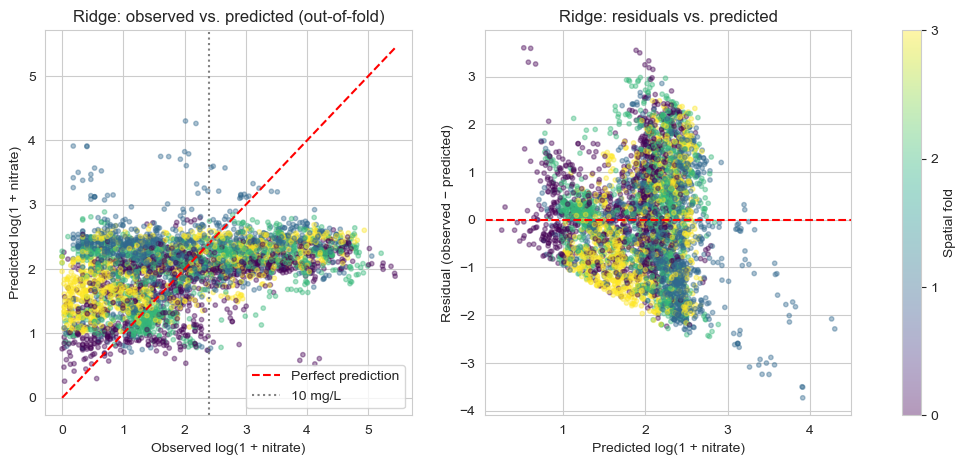

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

fold_colors = train_val["fold"].astype(int)
residuals = y_tv - ridge_oof

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
sc = axs[0].scatter(y_tv, ridge_oof, c=fold_colors, cmap="viridis", alpha=0.4, s=10)
lims = [0, y_tv.max()]
axs[0].plot(lims, lims, "r--", label="Perfect prediction")
axs[0].axvline(np.log1p(10), color="gray", linestyle=":", label="10 mg/L")
axs[0].set_xlabel("Observed log(1 + nitrate)")
axs[0].set_ylabel("Predicted log(1 + nitrate)")
axs[0].set_title("Ridge: observed vs. predicted (out-of-fold)")
axs[0].legend()

axs[1].scatter(ridge_oof, residuals, c=fold_colors, cmap="viridis", alpha=0.4, s=10)
axs[1].axhline(0, color="r", linestyle="--")
axs[1].set_xlabel("Predicted log(1 + nitrate)")
axs[1].set_ylabel("Residual (observed − predicted)")
axs[1].set_title("Ridge: residuals vs. predicted")
fig.colorbar(sc, ax=axs, label="Spatial fold", ticks=[0, 1, 2, 3])
plt.show()

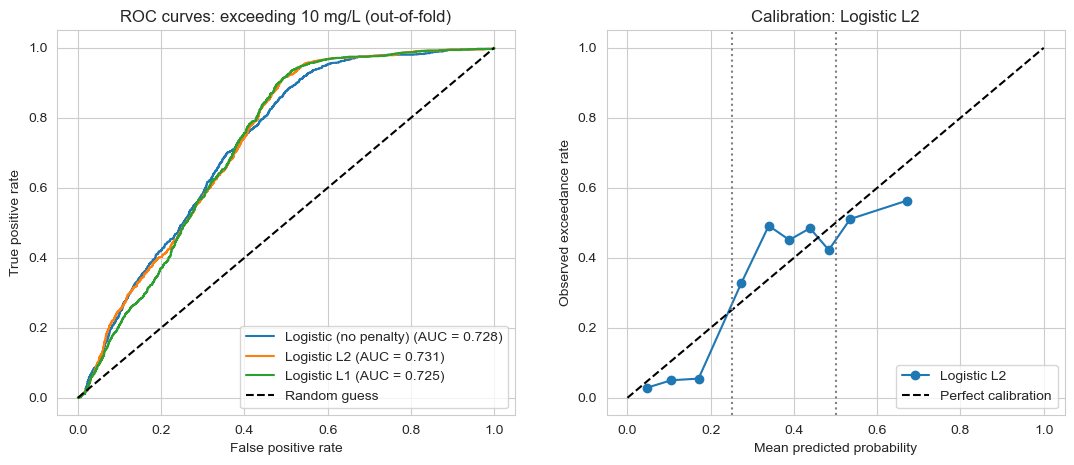

In [14]:
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for name, p in {"Logistic (no penalty)": logit_oof,
                "Logistic L2": logit_l2_oof,
                "Logistic L1": logit_l1_oof}.items():
    fpr, tpr, _ = roc_curve(exceeds_tv, p)
    axs[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(exceeds_tv, p):.3f})")
axs[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axs[0].set_xlabel("False positive rate")
axs[0].set_ylabel("True positive rate")
axs[0].set_title("ROC curves: exceeding 10 mg/L (out-of-fold)")
axs[0].legend()

prob_true, prob_pred = calibration_curve(exceeds_tv, logit_l2_oof, n_bins=10, strategy="quantile")
axs[1].plot(prob_pred, prob_true, "o-", label="Logistic L2")
axs[1].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for cut in [0.25, 0.5]:
    axs[1].axvline(cut, color="gray", linestyle=":")
axs[1].set_xlabel("Mean predicted probability")
axs[1].set_ylabel("Observed exceedance rate")
axs[1].set_title("Calibration: Logistic L2")
axs[1].legend()
plt.show()

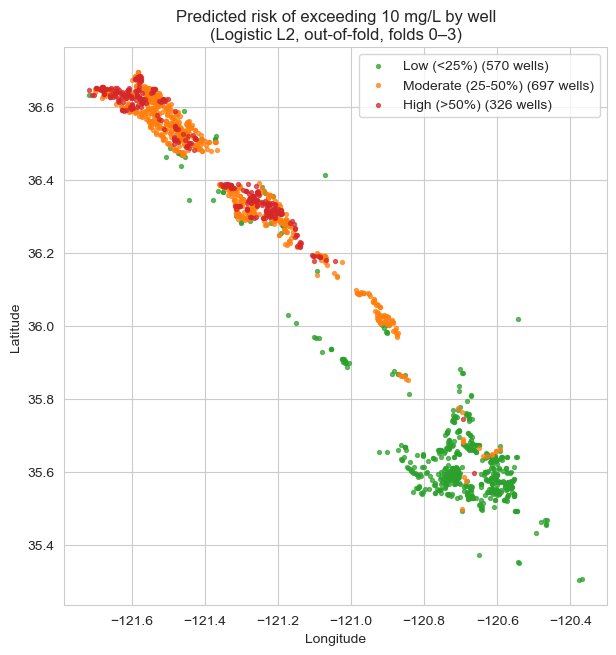

In [15]:
well_risk = (train_val.assign(prob=logit_l2_oof)
             .groupby("gm_well_id")
             .agg(lat=("gm_latitude", "first"), lon=("gm_longitude", "first"), prob=("prob", "mean")))
well_risk["risk_level"] = pd.cut(well_risk["prob"], [0, 0.25, 0.5, 1.0001], right=False,
                                 labels=["Low (<25%)", "Moderate (25-50%)", "High (>50%)"])

colors = {"Low (<25%)": "tab:green", "Moderate (25-50%)": "tab:orange", "High (>50%)": "tab:red"}
plt.figure(figsize=(7, 8))
for level, color in colors.items():
    sub = well_risk[well_risk["risk_level"] == level]
    plt.scatter(sub["lon"], sub["lat"], s=8, color=color, alpha=0.7, label=f"{level} ({len(sub)} wells)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Predicted risk of exceeding 10 mg/L by well\n(Logistic L2, out-of-fold, folds 0–3)")
plt.legend()
plt.gca().set_aspect("equal")
plt.show()

## 5. Conclusions

**Regression (log nitrate)**
- Ridge performed best (RMSE 1.141 vs. 1.238 for the dummy baseline, about 8% lower; R² = 0.145), with Lasso close behind (RMSE 1.145).
- Unpenalized linear regression was unstable in unseen areas: in fold 1 it predicted worse than the mean (R² = −0.29). Regularization reduced this (Ridge R² = −0.09 in fold 1).
- The selected Ridge penalties were large (alpha = 3,162–10,000), reflecting strong collinearity among agricultural, terrain, and climate predictors. Ridge likely edges out Lasso because it spreads weight across correlated features instead of keeping only one per group.

**Probability of exceeding 10 mg/L**
- L2 logistic regression performed best (mean AUC = 0.738; mean Brier skill = 0.135), followed by L1 (Brier skill = 0.124) and no penalty (0.091).
- Fold 1 was again the weakest (AUC ≈ 0.62–0.65, negative Brier skill), indicating a region where linear models do not transfer well.

**Risk levels (L2 logistic, out-of-fold)**
- *Low* (< 25%) is reliable: 5.3% of these 1,350 samples exceeded 10 mg/L.
- *Moderate* (25–50%) and *High* (> 50%) are poorly separated (44.5% vs. 53.4% observed exceedance), so linear models identify low-risk areas well but cannot distinguish among higher-risk areas.

**Interpretation and next steps**
- Linear models capture broad gradients in nitrate risk but leave most of the variation unexplained, consistent with nonlinear relationships and interactions (e.g., between crops, soils, and terrain) that linear models cannot represent. They serve as an interpretable reference for the tree-based models.
- Results should be compared with the decision tree, random forest, and gradient boosting notebooks on the same folds, paying particular attention to fold 1.

**Caveats:** results use folds 0–3 only; the fold 4 holdout has not been used. Errors are on the log scale. Coefficients and associations are not causal effects.
- Out-of-fold predictions are compressed toward the mean (predicted log nitrate ≈ 1–2.6 vs. observed 0–5.4): the model overestimates low-nitrate wells and underestimates the most contaminated ones.
- Predicted probabilities are well calibrated below ~25% but flatten at ~45–55% observed exceedance above ~30%, explaining why Moderate and High risk levels are poorly separated. Predicted risk follows a north–south gradient, with higher risk in the northern (lower) Salinas Valley.

In [16]:
# ============================================================
# FINAL EVALUATION ON THE HOLD-OUT FOLD
# Run this ONCE, for the final chosen model only, after all
# model choices (features, hyperparameters) are finished.
# ============================================================
#RUN_FINAL_EVALUATION = False

#if RUN_FINAL_EVALUATION:
    #holdout_df = df[df["holdout"]].reset_index(drop=True)
   # final_model = ...                      # the chosen model, refit on all of train_val
    #final_model.fit(X, y)
   # holdout_pred = final_model.predict(holdout_df[FEATURES])
    ...                                    # scores on np.log1p(holdout_df[TARGET])


IndentationError: unexpected indent (954871930.py, line 13)